# NUTDTS 816 Time Series Analysis
## L03 Decomposition I: models, moving averages, classical decomposition

Lab notebook for Chapter 2 of the lecture notes. Run the setup cell first. Every code cell reproduces an example from the notes; the exercises at the end are from the chapter's self-check list.

**Instructor:** Dr Tolulope Adesina · NUTM MSc Data Science · 2026

In [18]:
# ---- Setup: run once per Colab session ----
# 1. Install the course libraries (about two minutes the first time)
!pip install -q statsmodels pmdarima statsforecast neuralforecast lightgbm arch plotly

# 2. Fetch the course data module and data snapshots from the course repository.
#    Replace REPO with your fork or the official course repository URL.
REPO = "https://raw.githubusercontent.com/toadesina/NUTDTS816_Course_Repository/main"
import urllib.request, os
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
DATA_FILES = ["nigeria_cpi", "nigeria_fx", "nigeria_grid", "nigeria_malaria", "nigeria_rainfall", "bonny_light", "daily_demand",
              "airpassengers", "a10", "h02", "ausbeer", "elecequip", "usmelec", "goog", "nile", "austourists", "oil", "dax", "uschange", "elecdemand"]
for f in DATA_FILES:
    urllib.request.urlretrieve(f"{REPO}/data/{f}.csv", f"data/{f}.csv")

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
import tsdata
print("Setup complete.")

Setup complete.


### 2.1 Decomposition models

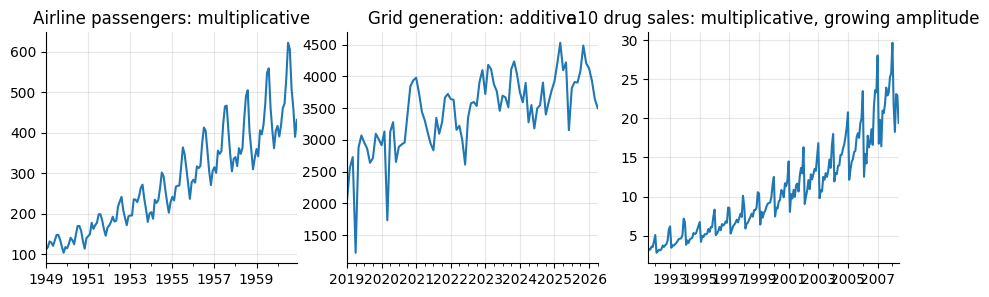

In [19]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import tsdata
ap   = tsdata.airpassengers()     # multiplicative
grid = tsdata.nigeria_grid()      # additive (simulated)
a10  = tsdata.a10()               # monthly antidiabetic drug sales, Australia: multiplicative, strong trend
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
ap.plot(ax=axes[0], title='Airline passengers: multiplicative')
grid.plot(ax=axes[1], title='Grid generation: additive')
a10.plot(ax=axes[2], title='a10 drug sales: multiplicative, growing amplitude')
for ax in axes: ax.set_xlabel('')
_caption = 'Two multiplicative series and one additive series.'

### 2.2 Estimating the trend with moving averages

First valid trend value: 1949-07-01 | last: 1960-06-01


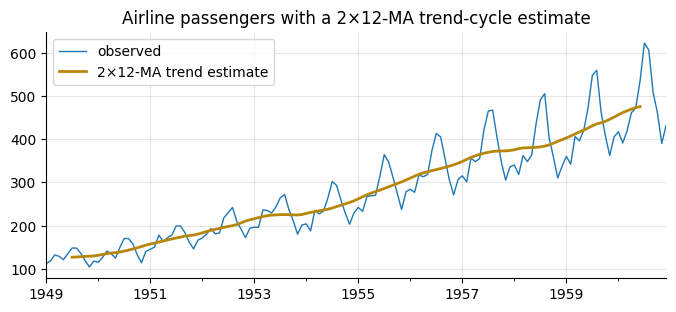

In [20]:
def centred_2xm_ma(s, m):
    """2 x m moving average (for even m) or m-MA (odd m)."""
    if m % 2 == 1:
        return s.rolling(m, center=True).mean()
    first = s.rolling(m).mean()                 # trailing m-MA
    return first.rolling(2).mean().shift(-m // 2)  # average adjacent pairs and recentre

t_hat = centred_2xm_ma(ap, 12)
ax = ap.plot(figsize=(8, 3.2), label='observed', lw=1)
t_hat.plot(ax=ax, color='#B8860B', lw=2, label='2×12-MA trend estimate')
ax.set_title('Airline passengers with a 2×12-MA trend-cycle estimate'); ax.legend(); ax.set_xlabel('')
print('First valid trend value:', t_hat.first_valid_index().date(), '| last:', t_hat.last_valid_index().date())
_caption = 'The moving average removes the annual pattern and most of the noise. Six months are lost at each end.'

### 2.3 Classical decomposition

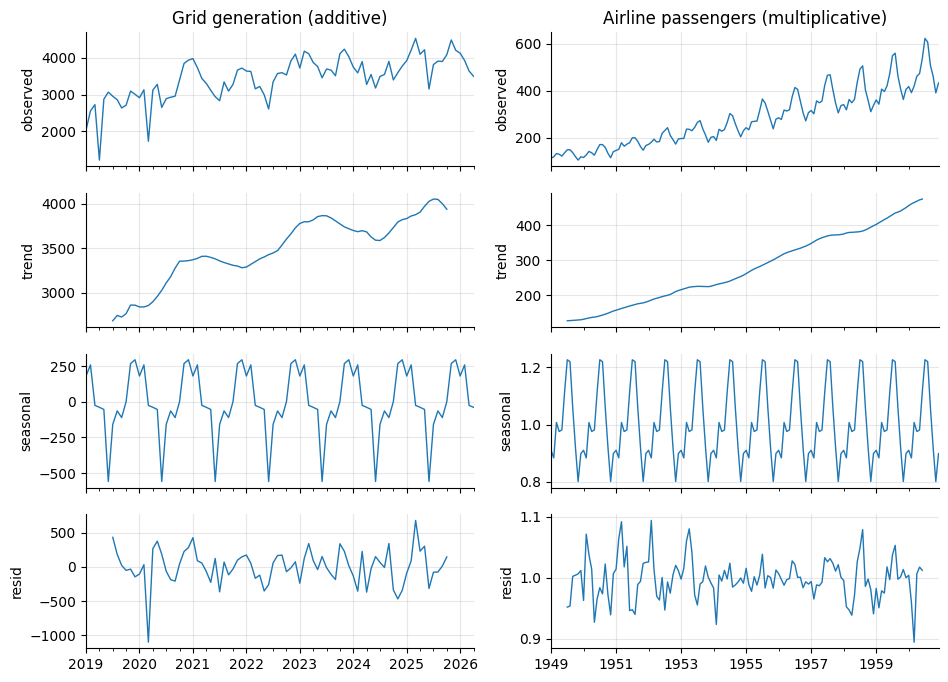

In [21]:
from statsmodels.tsa.seasonal import seasonal_decompose
dec_add  = seasonal_decompose(grid, model='additive', period=12)
dec_mult = seasonal_decompose(ap,   model='multiplicative', period=12)

fig, axes = plt.subplots(4, 2, figsize=(11, 8), sharex='col')
for col, (dec, name) in enumerate([(dec_add, 'Grid generation (additive)'), (dec_mult, 'Airline passengers (multiplicative)')]):
    for row, comp in enumerate(['observed', 'trend', 'seasonal', 'resid']):
        getattr(dec, comp).plot(ax=axes[row, col], lw=1); axes[row, col].set_ylabel(comp); axes[row, col].set_xlabel('')
    axes[0, col].set_title(name)
_caption = 'Classical decomposition panels. Note the gaps at the ends of trend and remainder, and the identical seasonal pattern every year.'

In [22]:
print('Seasonal factors, airline (multiplicative), one year:')
print(dec_mult.seasonal['1950'].round(3).to_string())
print('\nSeasonal effects, grid (additive, MW), one year:')
print(dec_add.seasonal['2020'].round(0).to_string())

Seasonal factors, airline (multiplicative), one year:
date
1950-01-01    0.910
1950-02-01    0.884
1950-03-01    1.007
1950-04-01    0.976
1950-05-01    0.981
1950-06-01    1.113
1950-07-01    1.227
1950-08-01    1.220
1950-09-01    1.060
1950-10-01    0.922
1950-11-01    0.801
1950-12-01    0.899
Freq: MS

Seasonal effects, grid (additive, MW), one year:
date
2020-01-01    182.0
2020-02-01    260.0
2020-03-01    -25.0
2020-04-01    -38.0
2020-05-01    -53.0
2020-06-01   -559.0
2020-07-01   -158.0
2020-08-01    -63.0
2020-09-01   -110.0
2020-10-01      2.0
2020-11-01    269.0
2020-12-01    296.0
Freq: MS


## Exercises

1. Write out the weights of a $2 \times 4$-MA and show that each quarter receives total weight $1/4$.
2. Decompose the `ausbeer` series (quarterly beer production, course data module) with classical and STL decompositions. In which years does the seasonal pattern change, and how does STL show it while classical decomposition cannot?
3. For the simulated `nigeria_grid()` series, compare the STL seasonal component with `seasonal=7` and `seasonal=25`. Which would you use for a five-year capacity plan, and why?

In [23]:
# Your work here
ausbeer = tsdata.ausbeer()


In [24]:
ausbeer.info()

<class 'pandas.core.series.Series'>
DatetimeIndex: 218 entries, 1956-01-01 to 2010-04-01
Freq: QS-JAN
Series name: beer
Non-Null Count  Dtype
--------------  -----
218 non-null    int64
dtypes: int64(1)
memory usage: 3.4 KB


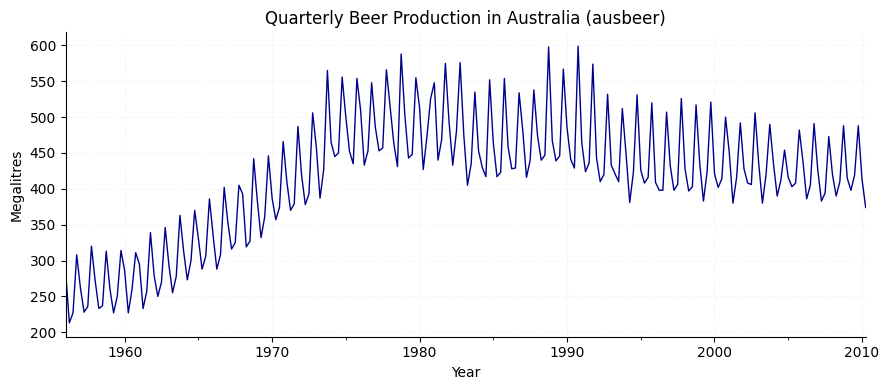

In [25]:
# Plotting the quarterly beer production (ausbeer)
plt.figure(figsize=(9, 4))
ausbeer.plot(lw=1, color='darkblue')
plt.title('Quarterly Beer Production in Australia (ausbeer)')
plt.ylabel('Megalitres')
plt.xlabel('Year')
plt.grid(True, linestyle='--', alpha=0.1)
plt.tight_layout()
plt.show()

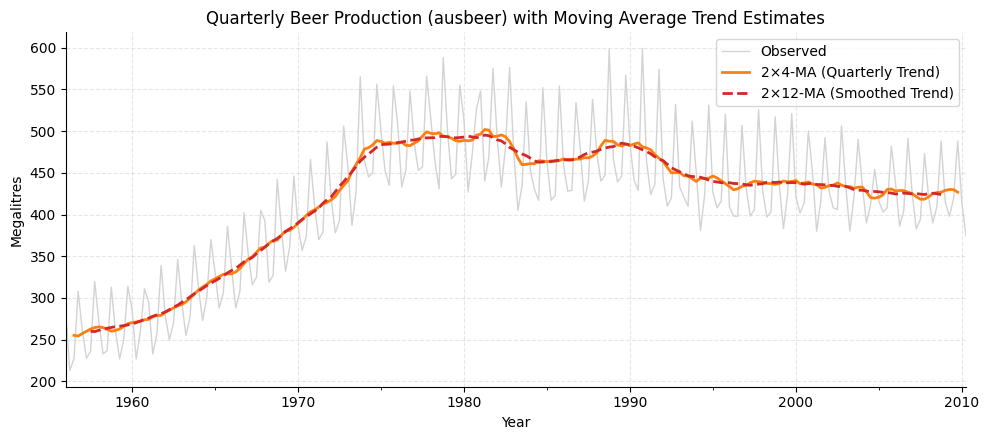

In [26]:
# Calculate 2x4-MA (appropriate for quarterly data) and 2x12-MA on ausbeer
t_hat_2x4 = centred_2xm_ma(ausbeer, 4)
t_hat_2x12 = centred_2xm_ma(ausbeer, 12)

# Plot the comparison
plt.figure(figsize=(10, 4.5))
ausbeer.plot(label='Observed', color='lightgray', lw=1)
t_hat_2x4.plot(label='2×4-MA (Quarterly Trend)', color='tab:orange', lw=2)
t_hat_2x12.plot(label='2×12-MA (Smoothed Trend)', color='tab:red', lw=2, linestyle='--')

plt.title('Quarterly Beer Production (ausbeer) with Moving Average Trend Estimates')
plt.ylabel('Megalitres')
plt.xlabel('Year')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

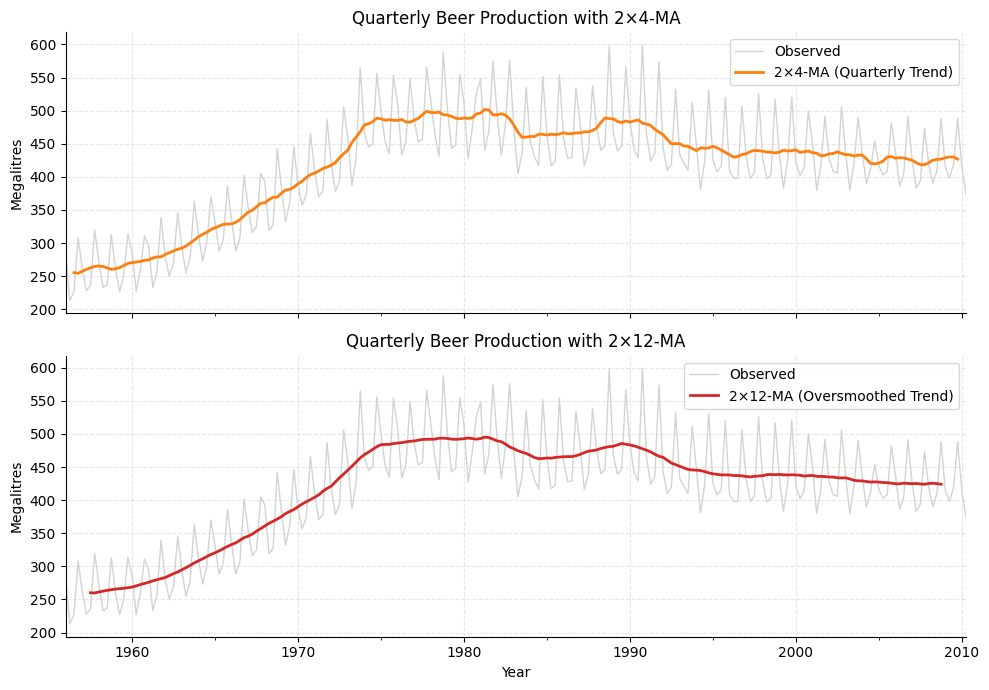

In [27]:
# Plot 2x4-MA and 2x12-MA on separate subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Subplot 1: 2x4-MA
ausbeer.plot(ax=axes[0], label='Observed', color='lightgray', lw=1)
t_hat_2x4.plot(ax=axes[0], label='2×4-MA (Quarterly Trend)', color='tab:orange', lw=2)
axes[0].set_title('Quarterly Beer Production with 2×4-MA')
axes[0].set_ylabel('Megalitres')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Subplot 2: 2x12-MA
ausbeer.plot(ax=axes[1], label='Observed', color='lightgray', lw=1)
t_hat_2x12.plot(ax=axes[1], label='2×12-MA (Oversmoothed Trend)', color='tab:red', lw=2)
axes[1].set_title('Quarterly Beer Production with 2×12-MA')
axes[1].set_ylabel('Megalitres')
axes[1].set_xlabel('Year')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
from scipy import stats
lam = stats.boxcox_normmax(ausbeer.values, method='mle')

In [29]:
lam

np.float64(1.4951084081140056)

MLE Box-Cox lambda for ausbeer: 1.495
Guerrero Box-Cox lambda for ausbeer: 0.205


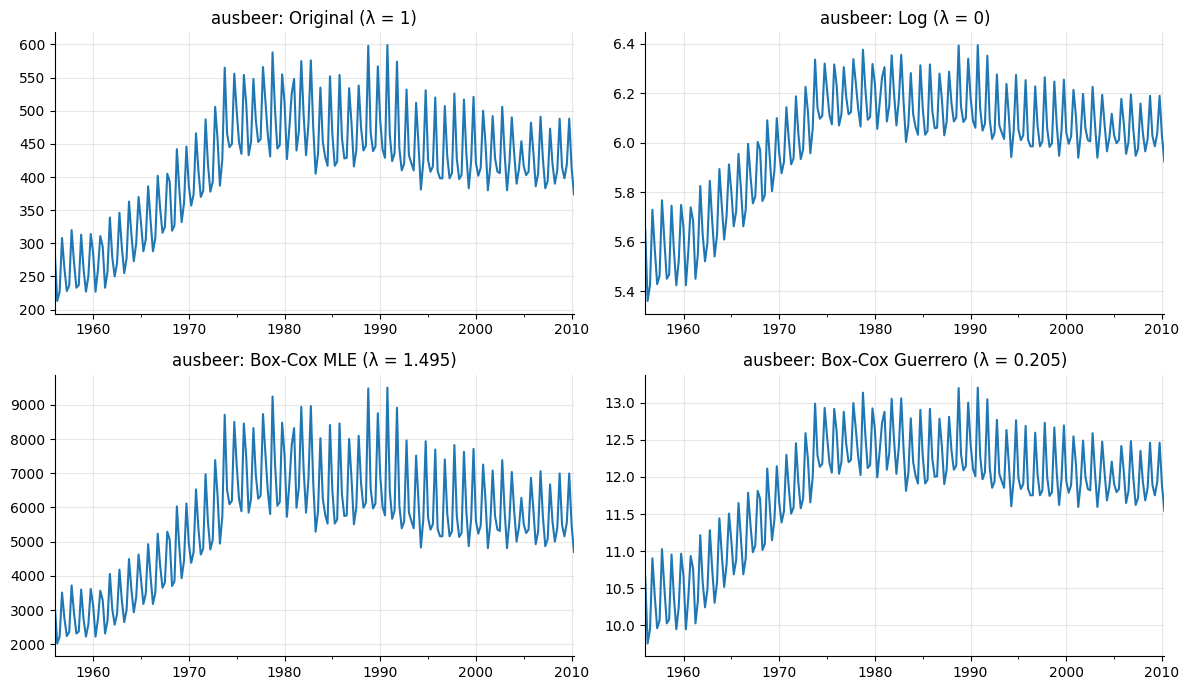

In [30]:
from scipy import stats
from coreforecast.scalers import boxcox_lambda
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estimate lambda using Maximum Likelihood Estimation
lam_mle = stats.boxcox_normmax(
    ausbeer.values, method='mle'
)

# Estimate lambda using Guerrero's method
lam_guerrero = boxcox_lambda(
    ausbeer.values,
    method='guerrero',
    season_length=4
)

print(f'MLE Box-Cox lambda for ausbeer: {lam_mle:.3f}')
print(f'Guerrero Box-Cox lambda for ausbeer: {lam_guerrero:.3f}')

# Apply transformations
ausbeer_mle = pd.Series(
    stats.boxcox(ausbeer.values, lmbda=lam_mle),
    index=ausbeer.index
)

ausbeer_guerrero = pd.Series(
    stats.boxcox(ausbeer.values, lmbda=lam_guerrero),
    index=ausbeer.index
)

# Compare the original and transformed series
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

ausbeer.plot(
    ax=axes[0, 0],
    title='ausbeer: Original (λ = 1)'
)

np.log(ausbeer).plot(
    ax=axes[0, 1],
    title='ausbeer: Log (λ = 0)'
)

ausbeer_mle.plot(
    ax=axes[1, 0],
    title=f'ausbeer: Box-Cox MLE (λ = {lam_mle:.3f})'
)

ausbeer_guerrero.plot(
    ax=axes[1, 1],
    title=f'ausbeer: Box-Cox Guerrero (λ = {lam_guerrero:.3f})'
)

for ax in axes.flat:
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

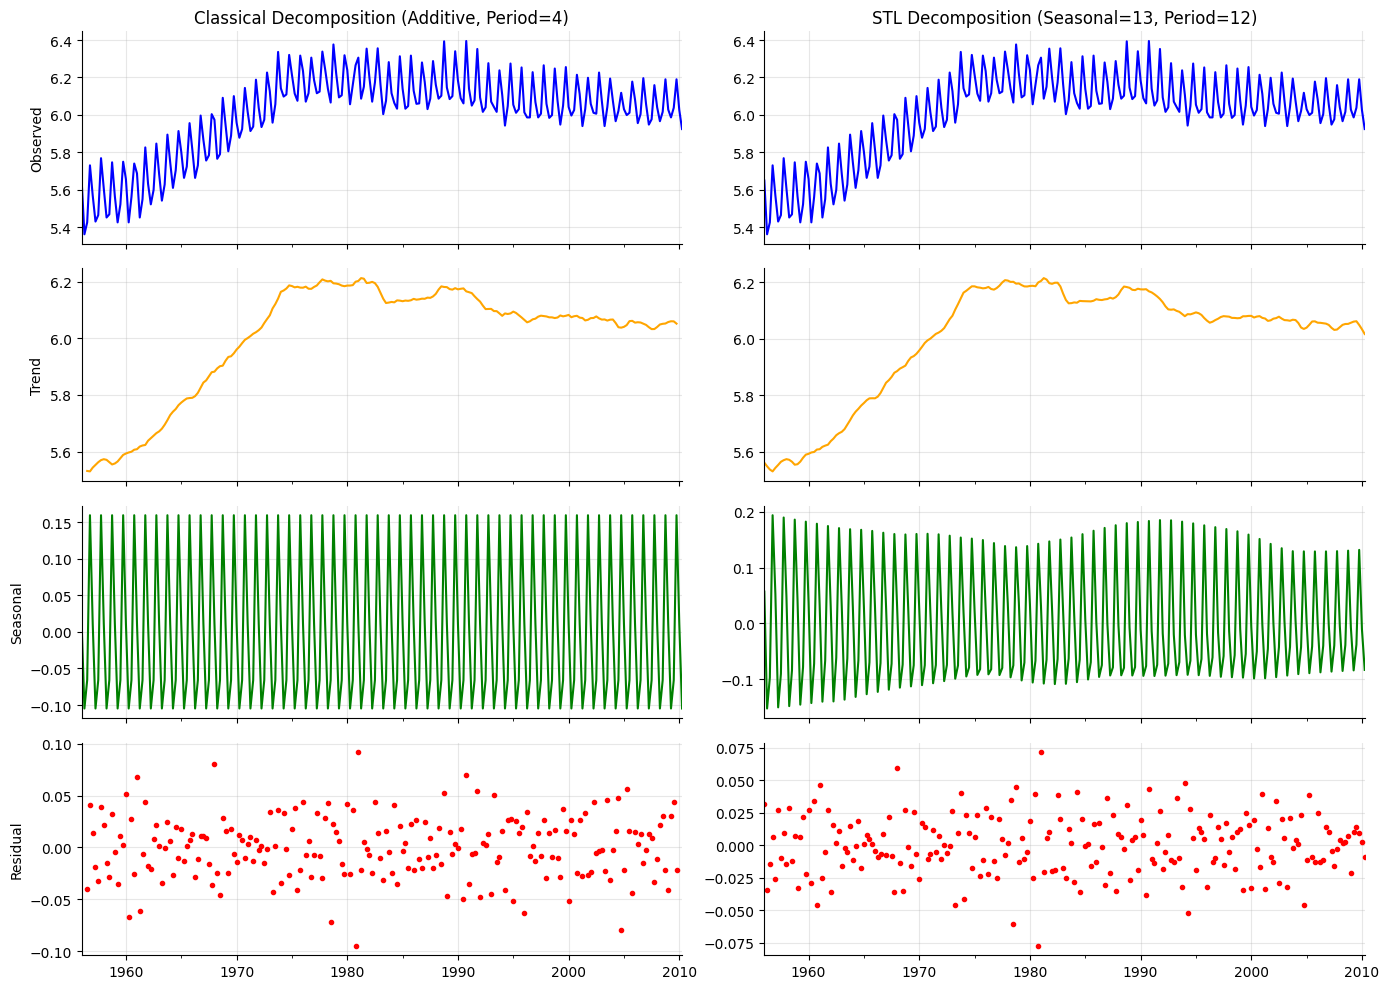

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL

# 1. Log transform the ausbeer series
ausbeer_log = np.log(ausbeer)

# 2. Additive Classical Decomposition (period=4 for quarterly data)
dec_classical = seasonal_decompose(ausbeer_log, model='additive', period=4)

# 3. STL Decomposition (seasonal=13, period=12 as requested)
dec_stl = STL(ausbeer_log, seasonal=13, period=4).fit()

# 4. Plotting the results
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

# Classical decomposition plots
axes[0, 0].set_title('Classical Decomposition (Additive, Period=4)')
dec_classical.observed.plot(ax=axes[0, 0], color='blue', legend=False)
axes[0, 0].set_ylabel('Observed')

dec_classical.trend.plot(ax=axes[1, 0], color='orange', legend=False)
axes[1, 0].set_ylabel('Trend')

dec_classical.seasonal.plot(ax=axes[2, 0], color='green', legend=False)
axes[2, 0].set_ylabel('Seasonal')

dec_classical.resid.plot(ax=axes[3, 0], color='red', legend=False, style='.')
axes[3, 0].set_ylabel('Residual')

# STL decomposition plots
axes[0, 1].set_title('STL Decomposition (Seasonal=13, Period=12)')
dec_stl.observed.plot(ax=axes[0, 1], color='blue', legend=False)

dec_stl.trend.plot(ax=axes[1, 1], color='orange', legend=False)

dec_stl.seasonal.plot(ax=axes[2, 1], color='green', legend=False)

dec_stl.resid.plot(ax=axes[3, 1], color='red', legend=False, style='.')

for ax in axes.flat:
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

In [33]:
nigeria_grid = tsdata.nigeria_grid()


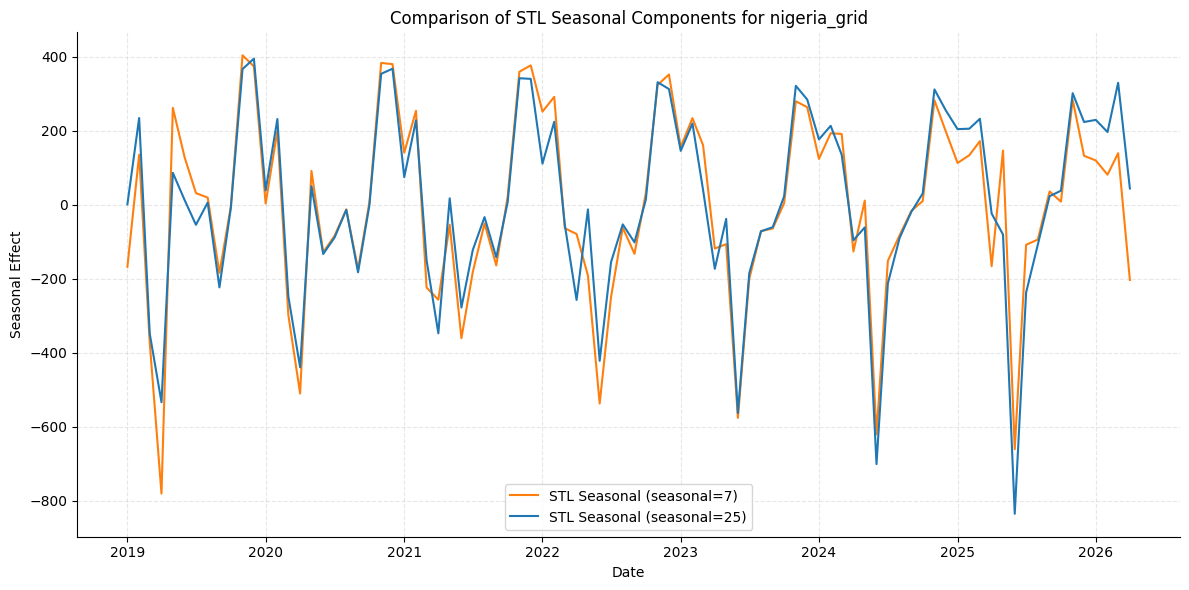

In [34]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# Perform STL decomposition with seasonal=7
stl_7 = STL(nigeria_grid, seasonal=7, period=12).fit()

# Perform STL decomposition with seasonal=25
stl_25 = STL(nigeria_grid, seasonal=25, period=12).fit()

# Plot and compare the seasonal components
plt.figure(figsize=(12, 6))
plt.plot(nigeria_grid.index, stl_7.seasonal, label='STL Seasonal (seasonal=7)', color='tab:orange', lw=1.5)
plt.plot(nigeria_grid.index, stl_25.seasonal, label='STL Seasonal (seasonal=25)', color='tab:blue', lw=1.5)

plt.title('Comparison of STL Seasonal Components for nigeria_grid')
plt.xlabel('Date')
plt.ylabel('Seasonal Effect')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

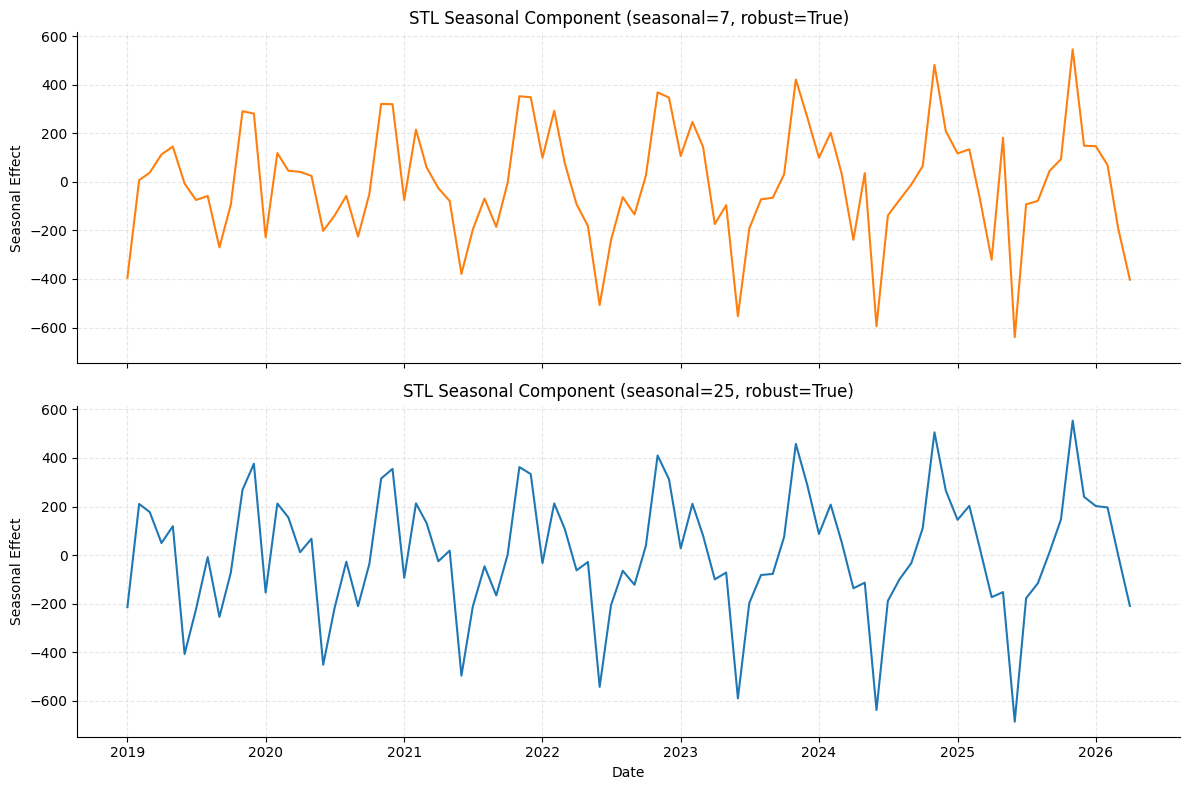

In [35]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# 1. STL with seasonal=7 and robust=True
stl_7_robust = STL(nigeria_grid, seasonal=7, period=12, robust=True).fit()

# 2. STL with seasonal=25 and robust=True
stl_25_robust = STL(nigeria_grid, seasonal=25, period=12, robust=True).fit()

# 3. Create two subplots
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, sharey=True)

# Plot for seasonal=7
axes[0].plot(nigeria_grid.index, stl_7_robust.seasonal, color='tab:orange', lw=1.5)
axes[0].set_title('STL Seasonal Component (seasonal=7, robust=True)')
axes[0].set_ylabel('Seasonal Effect')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Plot for seasonal=25
axes[1].plot(nigeria_grid.index, stl_25_robust.seasonal, color='tab:blue', lw=1.5)
axes[1].set_title('STL Seasonal Component (seasonal=25, robust=True)')
axes[1].set_ylabel('Seasonal Effect')
axes[1].set_xlabel('Date')
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()